# Advanced: Linear Regression Trained from Scratch with Gradient Descent

**Sub-topic 1.4 — Math and Statistics Essentials**

This is a toy version of the exact algorithm (in spirit — real neural networks add many layers and a much more complex loss surface, but the core loop is identical) used to train every neural network, including the LLMs you've been calling via API in earlier notebooks. Watching the loss curve go down on a problem simple enough to fully understand is one of the highest-leverage 10 minutes in this entire curriculum.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

LINE_COLOR = "#2E5EAA"

## Synthetic training data

Points roughly following `y = 3x + 7`, with a bit of noise — the "true" relationship the model has to discover from data alone.

In [2]:
def make_synthetic_data(n: int = 50, seed: int = 42) -> tuple[np.ndarray, np.ndarray]:
    rng = np.random.default_rng(seed)
    x = rng.uniform(0, 10, size=n)
    noise = rng.normal(0, 2, size=n)
    y = 3 * x + 7 + noise
    return x, y


x, y = make_synthetic_data()

## The loss function

Mean squared error: how wrong are the model's predictions, on average (squared so errors in both directions count, and big errors are penalized more than small ones).

In [3]:
def mean_squared_error(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    return float(np.mean((y_true - y_pred) ** 2))

## Gradient descent, from scratch

At every step:
1. Predict `y_hat = w*x + b` with the **current** `w`, `b`.
2. Measure how wrong that is (the loss).
3. Compute the **gradient**: the direction in which `w` and `b` would need to move to make the loss *worse*.
4. Step `w` and `b` a small distance in the **opposite** direction (downhill).
5. Repeat.

In [4]:
def train_linear_regression(
    x: np.ndarray, y: np.ndarray, learning_rate: float = 0.02, epochs: int = 500
) -> tuple[float, float, list[float]]:
    w, b = 0.0, 0.0  # start with a bad guess: a flat line at zero
    n = len(x)
    loss_history: list[float] = []

    for epoch in range(epochs):
        y_pred = w * x + b
        loss = mean_squared_error(y, y_pred)
        loss_history.append(loss)

        # Gradients of the MSE loss with respect to w and b (calculus,
        # worked out once by hand -- this is the only "derivative" math
        # in this whole notebook, and it's the same shape for every linear
        # model you'll ever fit).
        error = y_pred - y
        grad_w = (2 / n) * np.sum(error * x)
        grad_b = (2 / n) * np.sum(error)

        # The actual "descent" step: move opposite the gradient.
        w -= learning_rate * grad_w
        b -= learning_rate * grad_b

        if epoch % 100 == 0 or epoch == epochs - 1:
            print(f"  epoch {epoch:3d}:  loss={loss:8.3f}   w={w:.3f}  b={b:.3f}")

    return w, b, loss_history


print("Training linear regression with gradient descent")
print("(true relationship used to generate the data: y = 3x + 7 + noise)\n")
w, b, loss_history = train_linear_regression(x, y)

Training linear regression with gradient descent
(true relationship used to generate the data: y = 3x + 7 + noise)

  epoch   0:  loss= 589.252   w=5.799  b=0.909
  epoch 100:  loss=   3.715   w=3.404  b=3.972
  epoch 200:  loss=   2.562   w=3.189  b=5.424
  epoch 300:  loss=   2.344   w=3.096  b=6.054
  epoch 400:  loss=   2.303   w=3.055  b=6.327
  epoch 499:  loss=   2.296   w=3.038  b=6.445


In [5]:
print(f"Learned:  y = {w:.3f}*x + {b:.3f}")
print(f"Target:   y = 3.000*x + 7.000")
print(f"Initial loss: {loss_history[0]:.3f}  ->  Final loss: {loss_history[-1]:.3f}")

Learned:  y = 3.038*x + 6.445
Target:   y = 3.000*x + 7.000
Initial loss: 589.252  ->  Final loss: 2.296


## The loss curve

The single most-recognized chart shape in ML: a downward curve that flattens out as training converges.

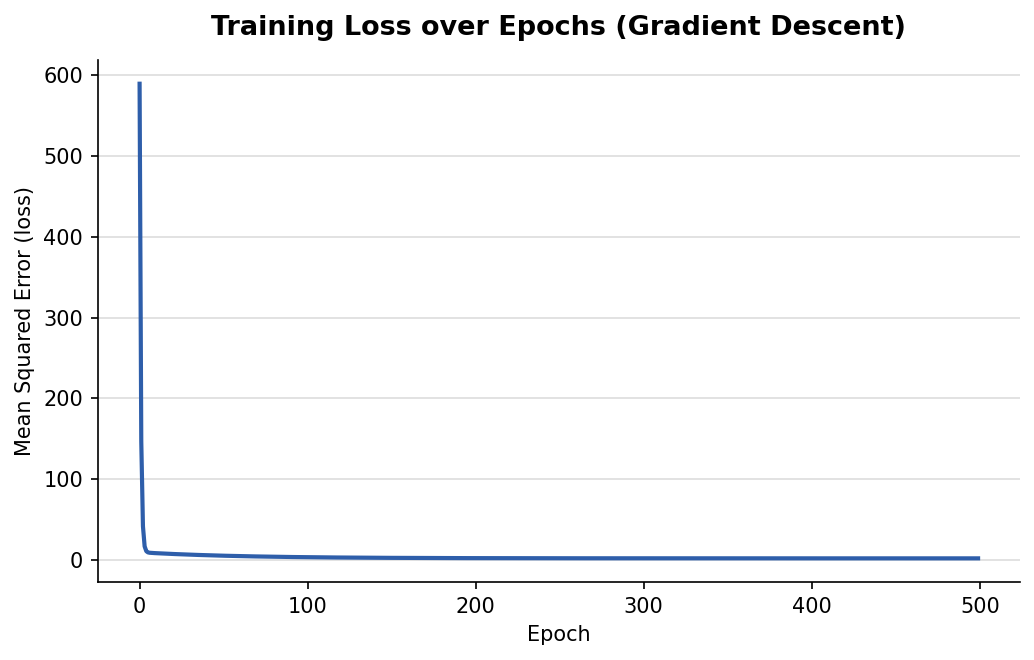

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=150)
ax.plot(loss_history, color=LINE_COLOR, linewidth=2)
ax.set_title("Training Loss over Epochs (Gradient Descent)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean Squared Error (loss)")
ax.grid(axis="y", color="#DDDDDD", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
fig.tight_layout()
plt.show()

## Interpretation

The loss starts high (the model's first guess, `w=0, b=0`, is bad) and decreases every epoch, flattening out as `w` and `b` converge close to the true values (3, 7). This "steep drop then flatten" shape is the same shape you'd see training a neural network with millions or billions of parameters — the mechanism (compute gradient, step opposite it, repeat) doesn't change, only the scale.

### Try it yourself
Change the learning rate (the step size in gradient descent) to something too large (e.g. `1.0`) and re-run. Observe what happens to the loss curve — your first hands-on encounter with a *diverging* training run, a real and common failure mode in ML.